# Post-training toolkit: pruning and neural-network quantization

This notebook starts with a trained activity-recognition network and asks a practical question: **how much smaller or faster can it become before its predictions get worse?** It brings the pruning and quantization tools into one place, with working examples, saved results, and instructions for running a new comparison.

The model takes roughly 2.56 seconds of smartphone motion readings and predicts one of six activities. You do not need to train it to read this notebook. The tables and charts use committed measurements. Optional examples can load local checkpoints, and QAT is a separate opt-in training step.

[Project overview](00_portfolio_summary.ipynb) · [Original model study](01_edge_sense.ipynb) · [Implementation guide](../docs/POST_TRAINING.md)

## Reading roadmap

Start with the common floating reference, distinguish zeros from removed channels, and then follow calibration, static PTQ, dynamic INT8, QAT, and their combination with pruning. Finish by comparing common-format deployment files and recomputing the selection rule. Keep RUN_LOCAL_EXAMPLES and RUN_QAT false to read saved evidence; enable them only after preparing their documented inputs.

Read the explanations before executing each block, and run cells in order: later blocks reuse variables created earlier. Saved output is a record of an earlier execution; running a report cell reads the report files currently in your checkout.


## Start with a reference you can compare against

A useful optimization comparison needs the same input data, a known starting checkpoint, a target runtime, and a consistent way to time it. A smaller weight file is not proof of faster execution. Zeros in a dense tensor do not automatically turn into sparse computation. Lower precision can add conversion overhead that matters for a tiny network.

The added experiments use one floating distilled student checkpoint, seed 7, and the existing subject-separated UCI HAR splits. Training fits weights and calibration ranges; validation selects epochs and candidates; test scores are reported after those choices. This is a single-checkpoint comparison, separate from the original three-seed study.

**Before you run:** Run setup before any comparison. It loads saved pruning and quantization reports and checks that they identify the same floating source checkpoint.

**How to read the output:** Matching source fingerprints make the starting point comparable; they do not make checkpoint bytes and deployment-archive bytes interchangeable. The assertions check recorded provenance and test-selection flags, without running conversion or training.


In [1]:
from pathlib import Path
import copy
import hashlib
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "reports/results.json").is_file())
q = json.loads((ROOT / "reports/quantization.json").read_text())
p = json.loads((ROOT / "reports/pruning.json").read_text())
original = json.loads((ROOT / "reports/results.json").read_text())
quantized = {c["name"]: c for c in q["candidates"]}
pruned = {c["name"]: c for c in p["candidates"]}

def table(headers, rows):
    def clean(v):
        return str(v).replace("|", " / ").replace("\n", " ")
    display(Markdown("| " + " | ".join(headers) + " |\n| " + " | ".join(["---"]*len(headers)) + " |\n" + "\n".join("| " + " | ".join(clean(v) for v in row) + " |" for row in rows)))

plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False})
print("Quantization report SHA256:", hashlib.sha256((ROOT / "reports/quantization.json").read_bytes()).hexdigest())
print("Pruning report SHA256:", hashlib.sha256((ROOT / "reports/pruning.json").read_bytes()).hexdigest())
assert q["source_sha256"] == p["source_sha256"]
assert not q["test_used_for_selection"] and not p["test_used_for_selection"]
print("The experiments share a source checkpoint. Saved backend:", q["torch_quantization_backend"])

Quantization report SHA256: bc7f0a2c1a502744de9e51154e97f474945817b88ed760738ce84e542fdefaf1
Pruning report SHA256: eafbccac92ea66968fc4fb4e12012db5f966748a07ec37eca2e793290bcb2f53
The experiments share a source checkpoint. Saved backend: qnnpack


## Which tool does what?

A network stores learned values called weights. During inference it combines input values with those weights to produce intermediate values called activations. There are two broad ways to reduce the work: remove parts of the network, or represent its numbers with fewer bits.

Pruning recovery and quantization-aware training need optimizer steps, so they are fine-tuning extensions to this toolkit. Static PTQ itself is training-free: it observes inputs without learning from labels. Distillation belongs to the original training stage rather than this post-training conversion step.

**Before you run:** Use this table to choose an operation before thinking about implementation. Calibration estimates numerical ranges from examples; fine-tuning updates learned weights.

**How to read the output:** Read the calibration and extra-training columns separately. A method can avoid weight training while still needing representative inputs, and a pruned model may need recovery training before it becomes a useful candidate.


In [2]:
table(["Method", "What changes", "Calibration", "Extra training"], [
    ("Magnitude pruning", "Individual small weights become zero; dimensions stay", "No", "Recovery fine-tuning here"),
    ("Channel pruning", "Channels and dependent dimensions are physically removed", "No", "Recovery fine-tuning here"),
    ("Dynamic INT8", "Linear weights use INT8; activation ranges computed at runtime", "No saved activation calibration", "No"),
    ("Static PTQ INT8", "Conv and linear weights/activations use quantized operators", "Representative training inputs", "No"),
    ("Channel pruning + PTQ", "Compact dimensions first, then quantize", "Training inputs after compaction", "Only earlier pruning recovery"),
    ("QAT", "Fake quantization during fine-tuning, then real INT8 conversion", "Training inputs", "Yes, with labels"),
    ("Core ML weight INT8", "Existing export compresses weights; activations stay float", "Not the static PTQ flow here", "No"),
])

| Method | What changes | Calibration | Extra training |
| --- | --- | --- | --- |
| Magnitude pruning | Individual small weights become zero; dimensions stay | No | Recovery fine-tuning here |
| Channel pruning | Channels and dependent dimensions are physically removed | No | Recovery fine-tuning here |
| Dynamic INT8 | Linear weights use INT8; activation ranges computed at runtime | No saved activation calibration | No |
| Static PTQ INT8 | Conv and linear weights/activations use quantized operators | Representative training inputs | No |
| Channel pruning + PTQ | Compact dimensions first, then quantize | Training inputs after compaction | Only earlier pruning recovery |
| QAT | Fake quantization during fine-tuning, then real INT8 conversion | Training inputs | Yes, with labels |
| Core ML weight INT8 | Existing export compresses weights; activations stay float | Not the static PTQ flow here | No |

## 1. Pruning: zeros and smaller layers are different results

Magnitude pruning ranks convolution and linear weights by absolute value and masks the smallest entries. In the 50% run, half of those weights become zero. The masks stay attached during fine-tuning, which prevents the removed connections from growing back. Removing the PyTorch pruning reparameterization writes the zeros into ordinary parameters; it does not undo the pruning.

Channel pruning keeps only selected output channels and builds a smaller dense network. The next layer must lose the matching input channels too. BatchNorm values and flattened channel/time positions must follow the same indices. This repository implements that mapping for its sequential student and rejects unsupported fusion models. The output still has six activity classes.

The table below measures real checkpoint files. The dense and magnitude-pruned files have the same dimensions and the same size. The compact networks have fewer parameters and smaller files. This does not assume a sparse runtime.

**Before you run:** Compare pruning candidates against both the unchanged model and the dense fine-tuning control. This keeps the effect of extra training visible.

**How to read the output:** Before/after validation F1 shows recovery; sparsity counts zeros; parameter count and checkpoint size show whether dimensions actually shrink. Use the later archive table for deployment-format comparisons.


| Candidate | Parameters | Zero weights | State checkpoint KiB | Val before tuning | Val after tuning | Test F1 |
| --- | --- | --- | --- | --- | --- | --- |
| dense_original | 13662 | 0% | 59.6 | 0.9602 | 0.9602 | 0.9139 |
| dense_finetuned | 13662 | 0% | 59.6 | 0.9602 | 0.9602 | 0.9139 |
| magnitude_50 | 13662 | 50% | 59.6 | 0.9485 | 0.9553 | 0.9209 |
| magnitude_70 | 13662 | 70% | 59.6 | 0.7342 | 0.9531 | 0.8832 |
| channels_75pct | 7980 | 0% | 37.7 | 0.5532 | 0.9672 | 0.8997 |
| channels_50pct | 3810 | 0% | 20.8 | 0.2901 | 0.9450 | 0.8969 |

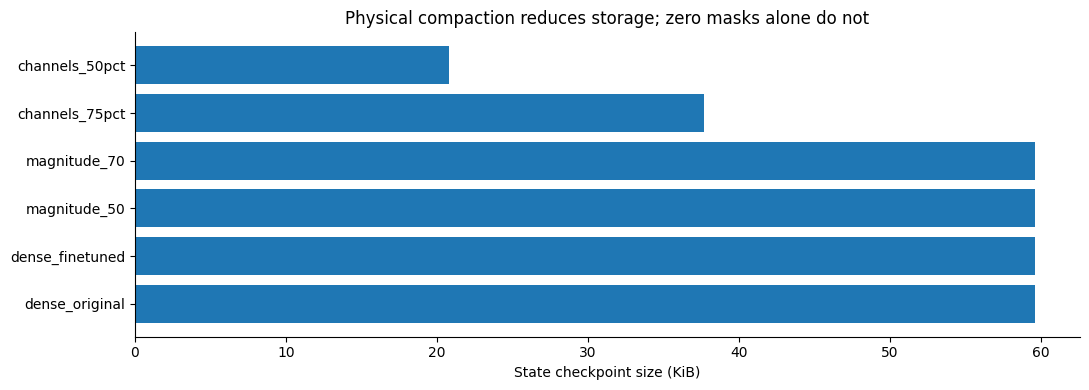

In [3]:
table(["Candidate", "Parameters", "Zero weights", "State checkpoint KiB", "Val before tuning", "Val after tuning", "Test F1"], [
    (c["name"], c["parameters"], f'{c["weight_sparsity"]:.0%}', f'{c["checkpoint_bytes"]/1024:.1f}',
     f'{c["before_finetuning_validation"]["macro_f1"]:.4f}', f'{c["validation"]["macro_f1"]:.4f}', f'{c["test"]["macro_f1"]:.4f}')
    for c in p["candidates"]])
fig, ax = plt.subplots()
ax.barh([c["name"] for c in p["candidates"]], [c["checkpoint_bytes"]/1024 for c in p["candidates"]])
ax.set(xlabel="State checkpoint size (KiB)", title="Physical compaction reduces storage; zero masks alone do not")
plt.tight_layout(); plt.show()

### Optional: create the two pruned forms

The following examples use the installed project package. Leave `RUN_LOCAL_EXAMPLES` false to read the saved study without needing checkpoints or datasets. Setting it true runs local conversion examples; it does not download missing files. Generate the checkpoint and prepared arrays using the commands at the end if needed.

This cell creates pruned models without training them. Their accuracy can fall sharply before recovery fine-tuning. `edge-prune --epochs 5` runs the full comparison, including the dense fine-tuning control, mask-preserving training, validation epoch selection, export checks, and repeated timing.

**Before you run:** Leave both switches false for the saved-results reading path. For live examples, enable RUN_LOCAL_EXAMPLES only after generating the floating checkpoint and prepared train/validation arrays; see the reproduction commands below.

**How to read the output:** The live branch creates independent pruned copies in memory. It performs no recovery training, so the compact example is not the measured fine-tuned candidate. Missing prerequisites raise an error. RUN_QAT is a separate opt-in used later.


In [4]:
RUN_LOCAL_EXAMPLES = False
RUN_QAT = False  # Separate opt-in: this runs labeled fine-tuning, not just conversion.

if RUN_LOCAL_EXAMPLES:
    import torch
    from edge_agent_lab.models import load_model
    from edge_agent_lab.data import ensure_data, load_split
    from edge_agent_lab.pruning import apply_magnitude_pruning, compact_channels, remove_masks, weight_sparsity
    from edge_agent_lab.quantization import prepare_static, assert_static_coverage, calibration_indices

    checkpoint = ROOT / "artifacts/edge/seed-7/distilled/model.pt"
    data_root = ROOT / "data/har"
    if not checkpoint.is_file() or not (data_root / "train.npz").is_file():
        raise FileNotFoundError("Generate the original checkpoint and prepared arrays first; see reproduction commands below.")
    ensure_data(data_root)
    source = load_model(checkpoint)
    training = load_split(data_root, "train")
    validation = load_split(data_root, "val")
    masked = copy.deepcopy(source)
    apply_magnitude_pruning(masked, amount=0.5)
    print("Masked weight sparsity:", weight_sparsity(masked))
    # Keep masks during any recovery training. Remove them only when exporting.
    remove_masks(masked)
    compact, kept_indices = compact_channels(source, width=source.width // 2)
    print("Original width:", source.width, "| compact width:", compact.width)
    print("No recovery training has run in this example.")
else:
    print("Local conversion examples disabled. Saved results above remain available.")

Local conversion examples disabled. Saved results above remain available.


## 2. What INT8 means for a neural network

A float32 number uses 32 bits. An 8-bit integer has 256 possible values. Quantization maps a range of real numbers onto those values using a scale and a zero point. Roughly, `real_value ≈ scale × (integer_value - zero_point)`. Rounding introduces error; values outside the chosen range can clip.

Weights have fixed values after training, so their range can be inspected directly. Activations depend on the input. Static PTQ uses **calibration**: representative training windows pass through the prepared model while observers estimate useful activation ranges. No gradients, labels, or weight updates are involved.

Dynamic INT8 already existed in the project, but it covers the linear layers only. The new static INT8 path converts **both convolutions and both linear layers**, including supported activations. Normalization, returned logits, and some graph boundaries remain float. This is broad network compute coverage, not a claim that every operator is integer.

## 3. Choose calibration data from training, not test

The saved run draws 512 training windows without replacement using seed 7. A 64-window prefix provides a calibration-size comparison. The rows below show whether all activity classes were represented. Calibration does not use those class labels to optimize weights; counts are a coverage check.

The exact indices and training file checksum are stored in the report. Existing training normalization stays embedded in the model. Calibration inputs therefore use the same raw sensor units as normal inference. Using validation or test inputs to fit ranges would leak information across the evaluation boundary.

**Before you run:** Inspect the training-only calibration sample before converting any network. This cell shows activity coverage for the nested 64- and 512-window subsets.

**How to read the output:** Counts describe coverage, not guaranteed representativeness. Uniqueness and total-count assertions check the recorded sample bookkeeping. The saved normalization and array fingerprint help identify the exact input preparation.


In [5]:
cal = q["calibration"]
labels = ["walking", "upstairs", "downstairs", "sitting", "standing", "lying"]
table(["Activity", "64 calibration windows", "512 calibration windows"], list(zip(labels, cal["subset64_class_counts"], cal["class_counts"])))
assert cal["split"] == "train"
assert len(cal["indices"]) == len(set(cal["indices"])) == cal["rows"]
assert sum(cal["class_counts"]) == cal["rows"]
print("Calibration training-array SHA256:", cal["split_sha256"])
print("Saved source normalization:", cal["normalization"])

| Activity | 64 calibration windows | 512 calibration windows |
| --- | --- | --- |
| walking | 18 | 95 |
| upstairs | 7 | 80 |
| downstairs | 8 | 69 |
| sitting | 8 | 90 |
| standing | 8 | 87 |
| lying | 15 | 91 |

Calibration training-array SHA256: 2f22ed624e612dfaf775ef1aac4edba305eb66815ed98a0b2a907cf4bdaa7871
Saved source normalization: source training statistics embedded in checkpoint


### Optional: convert and verify static PTQ

For the pinned PyTorch 2.2.2 environment, the helper calls `prepare_fx`, runs calibration with gradients disabled, then calls `convert_fx`. FX also fuses supported convolution/BatchNorm/ReLU patterns. Conversion must produce actual quantized layers; a model containing only fake quantizers is not a deployed INT8 model.

The coverage assertion below checks all four convolution/linear weight tensors. QNNPACK is the recorded CPU backend. These operators are not CUDA kernels, even on a machine that also has an NVIDIA GPU.

**Before you run:** If live examples are enabled, run the loading cell first. This step calibrates a copy of the floating source with training windows and converts supported layers into CPU INT8 operators.

**How to read the output:** The inventory should show converted convolution and linear weights. The output shape confirms that the converted model accepts a small validation batch; it does not establish full validation accuracy. With live examples disabled, the cell displays the saved inventory.


In [6]:
if RUN_LOCAL_EXAMPLES:
    indices = calibration_indices(len(training.x), count=512, seed=7)
    calibration = training.x[indices]
    int8_ptq = prepare_static(source, calibration, backend="qnnpack")
    inventory = assert_static_coverage(int8_ptq)
    table(["Layer", "Converted module", "Weight dtype", "Shape"], [
        (v["name"], v["module"], v["weight_dtype"], v["weight_shape"]) for v in inventory])
    with torch.inference_mode():
        logits = int8_ptq(torch.from_numpy(validation.x[:4]))
        print("Output shape:", tuple(logits.shape), "| output dtype:", logits.dtype)
else:
    table(["Layer", "Saved converted module", "Weight dtype", "Shape"], [
        (v["name"], v["module"], v["weight_dtype"], v["weight_shape"])
        for v in quantized["static_ptq_512"]["layers"]])
    assert all(v["quantized_weight"] for v in quantized["static_ptq_512"]["layers"])

| Layer | Saved converted module | Weight dtype | Shape |
| --- | --- | --- | --- |
| encoder.0 | ConvReLU1d | torch.qint8 | [24, 9, 5] |
| encoder.3 | ConvReLU1d | torch.qint8 | [24, 24, 5] |
| head.0 | LinearReLU | torch.qint8 | [48, 192] |
| head.3 | Linear | torch.qint8 | [6, 48] |

**Before you run:** Compare dynamic INT8 with the static conversion above. This path selects linear layers and does not collect calibration ranges for the convolutions.

**How to read the output:** Inspect which layers actually have quantized weights. The presence of INT8 somewhere in a model does not imply that every expensive layer uses integer computation. The example runs on CPU when enabled.


In [7]:
# Dynamic INT8 is a separate, simpler path. It does not calibrate the convolutions.
if RUN_LOCAL_EXAMPLES:
    from edge_agent_lab.quantization import layer_inventory
    dynamic_int8 = torch.ao.quantization.quantize_dynamic(
        copy.deepcopy(source), {torch.nn.Linear}, dtype=torch.qint8)
    table(["Layer", "Module", "Weight dtype", "Quantized weight"], [
        (v["name"], v["module"], v["weight_dtype"], v["quantized_weight"])
        for v in layer_inventory(dynamic_int8)])
    with torch.inference_mode():
        print("Dynamic INT8 output shape:", tuple(dynamic_int8(torch.from_numpy(validation.x[:4])).shape))
else:
    print("Saved dynamic coverage:", [(v["name"], v["quantized_weight"]) for v in quantized["dynamic_int8_linear"]["layers"]])

Saved dynamic coverage: [('encoder.0', False), ('encoder.3', False), ('head.0', True), ('head.3', True)]


### Look at the actual graph boundaries

The converted graph is included as text so it can be inspected without a model archive. `quantize_per_tensor` marks conversion into a quantized tensor; `dequantize` returns a float tensor. The graph also shows the floating input normalization. In this export, flatten has a float boundary before the linear section. Those conversions are part of real inference and are included in timing.

**Before you run:** Inspect the saved converted graph to understand where values enter and leave integer representation.

**How to read the output:** Look for quantize_per_tensor and dequantize around compute blocks. Float boundaries add work and affect timing. These text assertions establish that the saved graph contains conversion boundaries, not that every operation executes in INT8.


In [8]:
graph = (ROOT / "reports/static_int8_graph.txt").read_text()
print(graph)
assert "quantize_per_tensor" in graph and "dequantize" in graph

graph():
    %x : 'torch.Tensor' [num_users=1] = placeholder[target=x]
    %mean : [num_users=1] = get_attr[target=mean]
    %sub : [num_users=1] = call_function[target=operator.sub](args = (%x, %mean), kwargs = {})
    %scale : [num_users=1] = get_attr[target=scale]
    %truediv : [num_users=1] = call_function[target=operator.truediv](args = (%sub, %scale), kwargs = {})
    %_scale_0 : [num_users=1] = get_attr[target=_scale_0]
    %_zero_point_0 : [num_users=1] = get_attr[target=_zero_point_0]
    %quantize_per_tensor : [num_users=1] = call_function[target=torch.quantize_per_tensor](args = (%truediv, %_scale_0, %_zero_point_0, torch.quint8), kwargs = {})
    %encoder_0 : [num_users=1] = call_module[target=encoder.0](args = (%quantize_per_tensor,), kwargs = {})
    %encoder_3 : [num_users=1] = call_module[target=encoder.3](args = (%encoder_0,), kwargs = {})
    %encoder_6 : [num_users=1] = call_module[target=encoder.6](args = (%encoder_3,), kwargs = {})
    %dequantize_3 : [num_users=1

## 4. QAT: a fine-tuning fallback when PTQ loses too much

Quantization-aware training inserts fake quantizers during training. Forward passes simulate rounding while gradients allow weights to adapt. Before deployment, the model is converted into the same kind of real INT8 operators used by PTQ. Leaving fake quantization in a float model is not the same result.

The run initializes observers with training windows, then uses up to five labeled fine-tuning epochs. BatchNorm statistics freeze after the first epoch; observer ranges freeze after the second; fake quantization remains active. Validation scores are measured on a **converted INT8 candidate at every epoch**, not just on the training-time fake-quantized model.

The initialized converted candidate is also eligible as epoch zero. In this run, the later QAT epochs did not beat it. That is why the saved QAT result does not claim an accuracy recovery. A floating control receives the same learning rate, optimizer, seed, and training budget.

**Before you run:** Compare the saved float fine-tuning control with converted QAT candidates over epochs. Epoch zero is already a candidate and can win selection.

**How to read the output:** Higher validation macro F1 is better. A later epoch is not automatically an improvement; the selected epoch should follow validation quality. This plot reads recorded history and performs no training.


| Candidate | Selected epoch | Maximum fine-tuning epochs | Validation F1 |
| --- | --- | --- | --- |
| float_finetuned | 0 | 5 | 0.9602 |
| qat_int8 | 0 | 5 | 0.9575 |

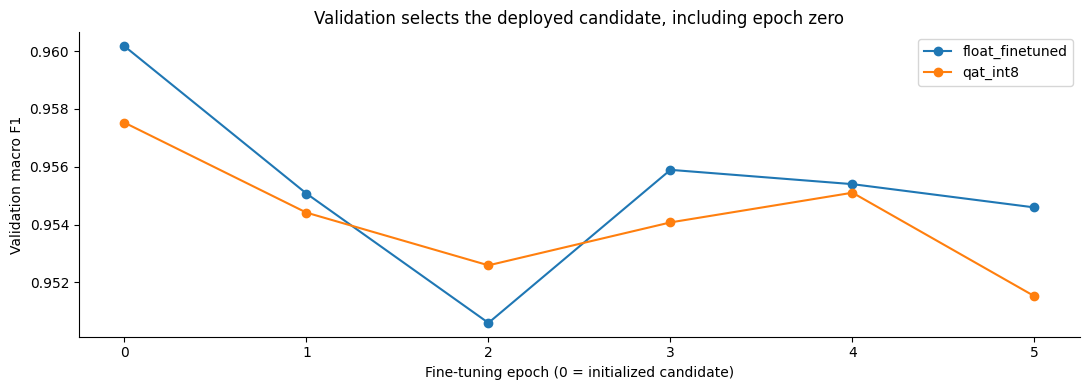

In [9]:
table(["Candidate", "Selected epoch", "Maximum fine-tuning epochs", "Validation F1"], [
    (name, quantized[name]["selected_finetuning_epoch"], q["fine_tuning_epochs"], f'{quantized[name]["validation"]["macro_f1"]:.4f}')
    for name in ["float_finetuned", "qat_int8"]])
fig, ax = plt.subplots()
for name in ["float_finetuned", "qat_int8"]:
    history = quantized[name]["history"]
    ax.plot([h["epoch"] for h in history], [h["validation_macro_f1"] for h in history], marker="o", label=name)
ax.set(xlabel="Fine-tuning epoch (0 = initialized candidate)", ylabel="Validation macro F1", title="Validation selects the deployed candidate, including epoch zero")
ax.legend(); plt.tight_layout(); plt.show()

**Before you run:** This cell trains only when RUN_QAT is true. Enable RUN_LOCAL_EXAMPLES and execute the preceding source-loading and static-calibration cells first so source, training, validation, and calibration are available.

**How to read the output:** The live branch initializes observers, performs up to five fine-tuning epochs, and converts the result to real INT8 layers. It can take longer than the report cells and changes in-memory weights. The disabled branch simply explains that the saved comparison remains available.


In [10]:
if RUN_QAT:
    if not RUN_LOCAL_EXAMPLES:
        raise ValueError("Enable RUN_LOCAL_EXAMPLES first to load the local data and source model.")
    from torch.ao.quantization import get_default_qat_qconfig_mapping
    from torch.ao.quantization.quantize_fx import prepare_qat_fx
    from edge_agent_lab.quantization import tune, set_backend

    set_backend("qnnpack")
    qat = prepare_qat_fx(copy.deepcopy(source).train(), get_default_qat_qconfig_mapping("qnnpack"),
                         (torch.from_numpy(calibration[:1]),))
    qat.eval()  # Initialize ranges without changing BatchNorm statistics.
    with torch.no_grad():
        for start in range(0, len(calibration), 64):
            qat(torch.from_numpy(calibration[start:start+64]))
    qat_int8, qat_history = tune(qat, training, validation, epochs=5, seed=7, qat=True)
    assert_static_coverage(qat_int8)
    print("QAT finished and converted to actual INT8 compute layers.")
else:
    print("QAT fine-tuning disabled. The saved five-epoch comparison is shown above.")

QAT fine-tuning disabled. The saved five-epoch comparison is shown above.


## 5. Combine physical channel pruning with PTQ

Once a channel-pruned network has been fine-tuned, it is an ordinary smaller floating network. PTQ can calibrate that network and convert its supported layers too. The order here is **compact → recovery fine-tune → calibrate → convert → evaluate**. Reuse training-only calibration windows, but collect fresh activation ranges for the compact network.

The measured combined candidate uses the saved half-width, fine-tuned checkpoint from the pruning study. It is not the untrained compact example created earlier in this notebook. Physical size reduction and lower precision can combine, but their accuracy costs still need measurement.

**Before you run:** The live combined example requires the recovered half-width pruning checkpoint, not merely the untuned compact model created earlier. Execute the calibration cells first.

**How to read the output:** Conversion collects ranges for this smaller network and checks INT8 coverage. If the compact checkpoint is absent, the example skips with a command to generate it. In report mode, the printed score belongs to the saved combined candidate.


In [11]:
if RUN_LOCAL_EXAMPLES:
    compact_path = ROOT / "artifacts/pruning/channels_50pct/model.pt"
    if compact_path.is_file():
        recovered_compact = load_model(compact_path)
        compact_int8 = prepare_static(recovered_compact, calibration, backend="qnnpack")
        assert_static_coverage(compact_int8)
        print("Recovered compact checkpoint converted to INT8.")
    else:
        print("Combined example skipped: run edge-prune --epochs 5 first.")
else:
    print("Saved compact source:", q["compact_checkpoint"])
    print("Compact PTQ validation F1:", round(quantized["compact_static_ptq_512"]["validation"]["macro_f1"], 4))

Saved compact source: {'path': 'artifacts/pruning/channels_50pct/model.pt', 'sha256': '7a8bb2589c00fbf45bdcd608ee8e20bf68c1c8dff2ba8760e5ba133c347acf90'}
Compact PTQ validation F1: 0.9462


## 6. Compare deployment files, accuracy, and measured timing

All rows in the next table use the same **TorchScript deployment archive format**, including the float controls. These sizes include graph and packed-weight metadata. They should not be compared directly with the earlier pruning table, which measures a different state-checkpoint format.

The loaded archive is what gets evaluated and timed. CPU inputs are already resident. Loading, softmax, transfers, and an application server are outside the timer. Three interleaved rounds with shuffled candidate order report the median of the per-round p95 measurements. Batch 1 measures a single-window call; batch 64 measures a whole batch, not an individual request.

The columns show both validation and test macro F1. The test score is reporting only. In the original data, these represent people not used for training or model selection.

**Before you run:** Compare candidates using the same deployment archive format. Read quality alongside archive size and batch-specific CPU p95 duration before judging a method.

**How to read the output:** Lower KiB and milliseconds are better; higher macro F1 is better. Batch-64 duration is time for a batch, not one window. The charts show storage and timing tradeoffs, while the table retains quality costs. All values come from saved runs on the recorded host.


| Candidate | Archive KiB | Validation F1 | Test F1 | CPU batch-1 p95 ms | CPU batch-64 p95 ms |
| --- | --- | --- | --- | --- | --- |
| float_original | 78.5 | 0.9602 | 0.9139 | 0.066 | 3.440 |
| float_finetuned | 79.4 | 0.9602 | 0.9139 | 0.066 | 3.448 |
| dynamic_int8_linear | 56.7 | 0.9602 | 0.9139 | 0.146 | 3.462 |
| static_ptq_64 | 39.7 | 0.9575 | 0.9143 | 0.060 | 0.602 |
| static_ptq_512 | 40.2 | 0.9582 | 0.9137 | 0.060 | 0.616 |
| qat_int8 | 40.2 | 0.9575 | 0.9129 | 0.060 | 0.604 |
| compact_float | 41.0 | 0.9450 | 0.8969 | 0.056 | 2.021 |
| compact_static_ptq_512 | 30.6 | 0.9462 | 0.8989 | 0.050 | 0.474 |

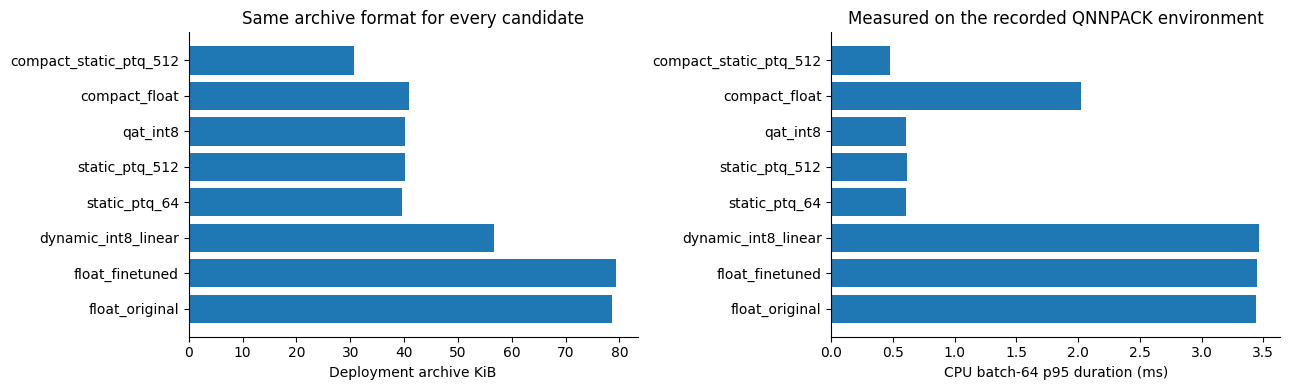

Static PTQ archive reduction: 1.95×
Static PTQ test F1 difference: -0.02 percentage points
These ratios describe this recorded environment, not a guarantee for another device.


In [12]:
table(["Candidate", "Archive KiB", "Validation F1", "Test F1", "CPU batch-1 p95 ms", "CPU batch-64 p95 ms"], [
    (c["name"], f'{c["archive_bytes"]/1024:.1f}', f'{c["validation"]["macro_f1"]:.4f}', f'{c["test"]["macro_f1"]:.4f}',
     f'{c["timing"]["batch1"]["p95_ms"]:.3f}', f'{c["timing"]["batch64"]["p95_ms"]:.3f}')
    for c in q["candidates"]])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
names = [c["name"] for c in q["candidates"]]
axes[0].barh(names, [c["archive_bytes"]/1024 for c in q["candidates"]])
axes[0].set(xlabel="Deployment archive KiB", title="Same archive format for every candidate")
axes[1].barh(names, [c["timing"]["batch64"]["p95_ms"] for c in q["candidates"]])
axes[1].set(xlabel="CPU batch-64 p95 duration (ms)", title="Measured on the recorded QNNPACK environment")
plt.tight_layout(); plt.show()
base, ptq = quantized["float_original"], quantized["static_ptq_512"]
print(f"Static PTQ archive reduction: {base['archive_bytes']/ptq['archive_bytes']:.2f}×")
print(f"Static PTQ test F1 difference: {100*(ptq['test']['macro_f1']-base['test']['macro_f1']):+.2f} percentage points")
print("These ratios describe this recorded environment, not a guarantee for another device.")

### Calibration size is worth checking, not assuming

The 64- and 512-window PTQ runs use nested training subsets. A larger set sees more input variation, but these two scores do not establish a general rule that more calibration windows always produce higher test quality. Ratios and sample counts were fixed before test evaluation. Both converted candidates quantize the same four compute layers.

**Before you run:** Compare the nested calibration subsets while keeping the conversion method fixed. This is a small sensitivity check on calibration size.

**How to read the output:** Validation F1 can inform the engineering comparison; test F1 is held-out reporting. Agreement with the float model measures matching predictions, not ground-truth correctness. Two subset sizes do not establish a universal calibration-size rule.


In [13]:
table(["PTQ calibration windows", "Validation F1", "Test F1", "Test top-1 agreement with original float"], [
    (count, f'{quantized[f"static_ptq_{count}"]["validation"]["macro_f1"]:.4f}',
     f'{quantized[f"static_ptq_{count}"]["test"]["macro_f1"]:.4f}',
     f'{quantized[f"static_ptq_{count}"]["test_top1_agreement_with_original_float"]:.2%}')
    for count in [64, 512]])
print("Dynamic INT8 can be slower than float here; measure the actual workload.")

| PTQ calibration windows | Validation F1 | Test F1 | Test top-1 agreement with original float |
| --- | --- | --- | --- |
| 64 | 0.9575 | 0.9143 | 99.69% |
| 512 | 0.9582 | 0.9137 | 99.56% |

Dynamic INT8 can be slower than float here; measure the actual workload.


## 7. Choose by a rule fixed before looking at test scores

The example rule permits up to 0.02 validation macro F1 loss relative to the original float model, then chooses the smallest archive. It does not choose by test F1 and does not claim that the smallest passing model has zero accuracy cost. A production target would also need an explicit latency, memory, and quality requirement measured on its own device.

**Before you run:** Recompute selection from validation quality and archive size. The rule first excludes candidates below the recorded floor, then picks the smallest passing archive.

**How to read the output:** Read the pass/fail table to see why a smaller candidate may be rejected. The assertion checks that this calculation matches the saved winner. The selected test F1 is printed afterward for reporting and never enters the selection expression.


In [14]:
floor = q["minimum_validation_f1"]
passing = [c for c in q["candidates"] if c["validation"]["macro_f1"] >= floor]
selected = min(passing, key=lambda c: (c["archive_bytes"], -c["validation"]["macro_f1"]))
assert selected["name"] == q["selected"]
print(f"Validation quality floor: {floor:.4f}")
print("Selected:", selected["name"])
print(f"Selected model test F1, reporting only: {selected['test']['macro_f1']:.4f}")
table(["Candidate", "Passes validation floor", "Archive bytes"], [
    (c["name"], c["validation"]["macro_f1"] >= floor, c["archive_bytes"]) for c in q["candidates"]])

Validation quality floor: 0.9402
Selected: compact_static_ptq_512
Selected model test F1, reporting only: 0.8989


| Candidate | Passes validation floor | Archive bytes |
| --- | --- | --- |
| float_original | True | 80433 |
| float_finetuned | True | 81299 |
| dynamic_int8_linear | True | 58023 |
| static_ptq_64 | True | 40627 |
| static_ptq_512 | True | 41199 |
| qat_int8 | True | 41199 |
| compact_float | True | 41969 |
| compact_static_ptq_512 | True | 31343 |

## 8. Load the deployed model and run it

An FX INT8 model has a different graph from `SensorNet`; it is not loaded by the ordinary floating-checkpoint helper. The exported `.ts` archive includes the inference graph and packed weights. Set the recorded engine and load it on CPU. The round-trip tests compare raw output scores before and after export, and evaluation uses the loaded archive.

This optional cell skips cleanly when local deployment files are absent. It uses validation input only and does not time file loading.

**Before you run:** For live loading, generate the static PTQ TorchScript archive, enable local examples, and load validation arrays in the earlier cells. This step uses the recorded CPU quantization engine.

**How to read the output:** The output lists predictions for four validation windows. A high softmax probability is model confidence, not proof that the predicted activity is correct. Missing archives skip cleanly; full accuracy and round-trip checks belong to the saved evaluation and reproduction workflow.


In [15]:
if RUN_LOCAL_EXAMPLES:
    archive = ROOT / "artifacts/quantization/static_ptq_512/model.ts"
    if archive.is_file():
        torch.backends.quantized.engine = q["torch_quantization_backend"]
        deployed = torch.jit.load(str(archive), map_location="cpu").eval()
        with torch.inference_mode():
            probabilities = deployed(torch.from_numpy(validation.x[:4])).softmax(1).numpy()
        table(["Window", "Predicted activity", "Probability"], [
            (i, labels[int(row.argmax())], f'{row.max():.3f}') for i, row in enumerate(probabilities)])
    else:
        print("Archive absent: run edge-quantize --epochs 5 first.")
else:
    assert all(c["archive_roundtrip_passed"] for c in q["candidates"])
    print("All saved candidates passed deployment archive round-trip verification.")

All saved candidates passed deployment archive round-trip verification.


## Runtime support: CPU INT8 is not automatically GPU INT8

| Artifact | Measured execution path | What to use on another machine |
|---|---|---|
| Floating original or channel-pruned checkpoint | CPU; CUDA/MPS supported by the separate inference helper | `edge-infer --device auto` or explicitly select a supported device |
| Dynamic or static INT8 TorchScript archive | CPU QNNPACK in this study | Install a compatible CPU build and select the recorded engine |
| Core ML compressed package | CPU_ONLY in the original export study | Recheck runtime placement and parity on the target Apple device |
| NVIDIA INT8 deployment | Not implemented or measured here | Requires a separate supported export/runtime such as TensorRT and NVIDIA verification |

Moving these QNNPACK graphs to CUDA is not a supported GPU optimization. CUDA or MPS floating-point inference is already available in the other notebooks. A GPU speedup should only be reported after measuring that GPU path with correct synchronization.

This repository pins PyTorch 2.2.2 for the original machine. It uses the FX APIs tested in that environment. Current PyTorch documentation directs newer quantization work toward **torchao / PT2E**. Migrating requires a separate environment and renewed checks for Conv1d coverage, export, and backend behavior; the APIs are not interchangeable just because their names sound similar.

## Reproduce the full toolkit

From the repository root, with the project environment installed:

```bash
# Generate data and a floating source checkpoint if they are missing.
edge-lab prepare
edge-lab train --seeds 7 --epochs 40 --compact

# Pruning, recovery training, exports, and CPU / available-GPU timing.
edge-prune --epochs 5

# Dynamic INT8, calibrated static INT8, QAT, and compact + INT8.
edge-quantize --epochs 5 --compact-checkpoint artifacts/pruning/channels_50pct/model.pt
```

`edge-prune` writes `reports/pruning.json`; `edge-quantize` writes `reports/quantization.json`. Checkpoints, deployment archives, and detailed graphs go under ignored `artifacts/`. These commands regenerate their dedicated reports and leave the original `reports/results.json` intact.

The notebook's local-example switches are off by default. To rerun the examples, install the project package, generate those local files, set `RUN_LOCAL_EXAMPLES = True`, and run all cells. Set `RUN_QAT = True` only when you also want to run its labeled fine-tuning step. Saved results remain the recorded comparison unless you rerun the experiment commands.

## What this run supports

Static PTQ cut deployment storage with little change in held-out macro F1 and improved CPU batch throughput on this host. Dynamic quantization covered fewer layers and was not faster for this tiny workload. Channel pruning saved additional space but cost held-out accuracy. QAT's later training epochs did not improve its initial converted validation result.

These are useful differences to inspect before choosing a tool. The next step for deployment is to repeat measurements on the actual target hardware and evaluate more seeds and representative inputs. No peak-memory, battery-life, GPU INT8, or broad statistical claim is made by these measurements.

Implementation: [quantization and runtime details](../docs/POST_TRAINING.md), [pruning details](../docs/PRUNING.md), [quantization report](../reports/QUANTIZATION.md), [pruning report](../reports/PRUNING.md).

Primary API references: [FX PTQ preparation](https://docs.pytorch.org/docs/stable/generated/torch.ao.quantization.quantize_fx.prepare_fx.html), [conversion](https://docs.pytorch.org/docs/main/generated/torch.ao.quantization.quantize_fx.convert_fx.html), [QAT preparation](https://docs.pytorch.org/docs/main/generated/torch.ao.quantization.quantize_fx.prepare_qat_fx.html), [pruning tutorial](https://docs.pytorch.org/tutorials/intermediate/pruning_tutorial.html), and [current quantization migration guidance](https://docs.pytorch.org/docs/main/quantization).